# Project Checkpoint 2
# Members: Alexander Sviriduk, Ashley Jenkins, Lauren Simms, Selena Lu, Yuan Yin
https://github.com/alex-sviriduk/maryland-precipitation-crashes/tree/clean-up/maryland_crash_data/raw 

In [204]:
%pip install openpyxl scipy adjustText


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# NOAA Weather Data: Exploration, Cleaning, and Setup

This notebook covers the first findings, setup, and cleaning of the NOAA weather data that we will be using alongside our car crash data for the Prince George's County area.

Our goal is to end up with the amount of precipitation per day for Prince George's County overall, for the dates 2019-2023.

We will be using pandas (imported as pd) to clean the data, along with numpy (imported as np). We are loading the NOAA weather data for the Prince George's County region into a pandas DataFrame.

In [205]:
import pandas as pd
import numpy as np

In [206]:
# Load the raw NOAA CSV
weather_raw = pd.read_csv("Precipitation2015-2020.csv")

## First Look at the Raw Data

We will now take a first look at the raw data, before changing anything. This is often called initial data inspection or exploratory data analysis. We will use pandas functions such as .head(), .info(), .describe(), and .isna().sum() to check the size of the data, the column types, the missing values, and the range of the values, so we can spot anything that looks wrong or messy.

In [207]:
weather_raw.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,DAPR,MDPR,PRCP,SNOW,SNWD
0,US1MDPG0073,"UPPER MARLBORO 1.7 N, MD US",38.842453,-76.752502,44.2,2015-04-06,NaN,NaN,0.00,0.0,NaN
1,US1MDPG0073,"UPPER MARLBORO 1.7 N, MD US",38.842453,-76.752502,44.2,2015-04-07,NaN,NaN,0.03,NaN,NaN
2,US1MDPG0073,"UPPER MARLBORO 1.7 N, MD US",38.842453,-76.752502,44.2,2015-04-08,NaN,NaN,0.06,NaN,NaN
3,US1MDPG0073,"UPPER MARLBORO 1.7 N, MD US",38.842453,-76.752502,44.2,2015-04-09,NaN,NaN,0.05,NaN,NaN
4,US1MDPG0073,"UPPER MARLBORO 1.7 N, MD US",38.842453,-76.752502,44.2,2015-04-10,NaN,NaN,0.05,NaN,NaN


In [208]:
weather_raw.shape

(51046, 11)

In [209]:
weather_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 51046 entries, 0 to 51045
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    51046 non-null  str    
 1   NAME       51046 non-null  str    
 2   LATITUDE   51046 non-null  float64
 3   LONGITUDE  51046 non-null  float64
 4   ELEVATION  51046 non-null  float64
 5   DATE       51046 non-null  str    
 6   DAPR       814 non-null    float64
 7   MDPR       811 non-null    float64
 8   PRCP       49532 non-null  float64
 9   SNOW       29398 non-null  float64
 10  SNWD       8831 non-null   float64
dtypes: float64(8), str(3)
memory usage: 4.3 MB


In [210]:
weather_raw.describe()

,LATITUDE,LONGITUDE,ELEVATION,DAPR,MDPR,PRCP,SNOW,SNWD
count,51046.000000,51046.000000,51046.000000,814.000000,811.000000,49532.000000,29398.000000,8831.000000
mean,38.923028,-76.873867,57.965555,5.477887,0.695290,0.137899,0.055225,0.423791
std,0.136056,0.098596,45.480931,5.473306,0.922346,0.364326,0.506977,1.624508
min,38.665455,-77.028948,7.300000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,38.822430,-76.931940,30.800000,2.000000,0.050000,0.000000,0.000000,0.000000
50%,38.968891,-76.902013,44.500000,3.000000,0.370000,0.000000,0.000000,0.000000
75%,39.030200,-76.768300,65.200000,7.000000,1.000000,0.070000,0.000000,0.000000
max,39.117498,-76.678062,248.100000,62.000000,8.680000,8.360000,17.400000,24.000000


In [211]:
weather_raw.isna().sum()

STATION          0
NAME             0
LATITUDE         0
LONGITUDE        0
ELEVATION        0
DATE             0
DAPR         50232
MDPR         50235
PRCP          1514
SNOW         21648
SNWD         42215
dtype: int64

In [212]:
weather_raw["DATE"].agg(["min", "max"])

min    2014-01-01
max    2026-01-01
Name: DATE, dtype: str

Things we need to fix, in order:

1. I noticed the dates are stored as text and not as a datetime type. We also have to filter by date to 2019-2023 to get our desired range.

In [213]:
# Work on a copy so weather_raw stays untouched
weather = weather_raw.copy()

# Convert DATE from text to datetime
weather["DATE"] = pd.to_datetime(weather["DATE"])

In [214]:
weather["DATE"].dtype

dtype('<M8[us]')

In [215]:
# Keep only dates from 2019-01-01 to 2023-12-31, then renumber the rows
weather = weather[(weather["DATE"] >= "2019-01-01") & (weather["DATE"] <= "2023-12-31")].reset_index(drop=True)

In [216]:
# Confirm row/column counts and the new date range
print(weather.shape)
weather["DATE"].agg(["min", "max"])

(20106, 11)


min   2019-01-01
max   2023-12-31
Name: DATE, dtype: datetime64[us]

2. Before renaming, we will drop the columns we do not need, so we do not spend time cleaning and renaming them.

Columns we are dropping and why:

- **SNOW and SNWD (snowfall and snow depth):** the precipitation column already includes snow, measured as melted water. Snow only shows up on about 2% of the days (43 of 1,826), and the columns are mostly blank (44% and 85%).
- **DAPR and MDPR (multi-day totals):** these are rain totals spread over several days, so they cannot be assigned to a single date and we cannot use them for the daily county average. The rows they sit on have a blank precipitation value, which we will deal with when we handle the missing precipitation values.

In [217]:
# Drop snow columns and multi-day total columns
weather = weather.drop(columns=["SNOW", "SNWD", "DAPR", "MDPR"])

In [218]:
weather.columns

Index(['STATION', 'NAME', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'DATE',
       'PRCP'],
      dtype='str')

3. The next step is to rename the columns, because the naming is a little unclear.

In [219]:
# Rename columns to clear names with units
weather = weather.rename(columns={
    "STATION": "station_id",
    "NAME": "station_name",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude",
    "ELEVATION": "elevation_meters",
    "DATE": "date",
    "PRCP": "precipitation_inches",
})

In [220]:
weather.head()

,station_id,station_name,latitude,longitude,elevation_meters,date,precipitation_inches
0,US1MDPG0050,"BOWIE 3.9 S, MD US",38.903576,-76.725861,38.7,2019-01-03,NaN
1,US1MDPG0050,"BOWIE 3.9 S, MD US",38.903576,-76.725861,38.7,2019-01-05,0.14
2,US1MDPG0050,"BOWIE 3.9 S, MD US",38.903576,-76.725861,38.7,2019-01-06,0.02
3,US1MDPG0050,"BOWIE 3.9 S, MD US",38.903576,-76.725861,38.7,2019-01-08,0.11
4,US1MDPG0050,"BOWIE 3.9 S, MD US",38.903576,-76.725861,38.7,2019-01-09,0.17


4. Next we check the blank precipitation values, to see how many there are and whether it is safe to drop them.

In [221]:
# Count blank precipitation values and their share of all rows
blank_count = weather["precipitation_inches"].isna().sum()
total_rows = len(weather)
print(f"Blank precipitation rows: {blank_count} of {total_rows} ({blank_count / total_rows:.1%})")

Blank precipitation rows: 214 of 20106 (1.1%)


Only 214 of the 20,106 rows (1.1%) have a blank precipitation value. That is negligible compared to the rest of the data, so it is ok to drop them.

**Why they are possibly missing:** the file does not say, but the pattern suggests two causes.

- Most of them (175) were rows where the rain was reported as a multi-day total instead of a daily value, probably because the gauge was not read for several days.
- Most of the rest (39) come from one station, Greenbelt 1.0 N, which appears to report snow but not rain.

In [222]:
# Drop rows with a blank precipitation value
weather = weather.dropna(subset=["precipitation_inches"]).reset_index(drop=True)

In [223]:
# Confirm rows left and that no blanks remain
print(weather.shape)
weather["precipitation_inches"].isna().sum()

(19892, 7)


np.int64(0)

5. We also know some stations are missing days entirely: there are about 7,000 station-days where a station was running but has no row for that day. We are not doing anything about these in the cleaning, because the missing days are not in the data to fix, and filling them in would invent rain (a 0 would wrongly say it was a dry day). Every day in 2019-2023 still has readings from at least 5 stations. We will account for this later, when we combine the stations, by keeping track of how many stations reported each day.

Column guide for weather (cleaned station data). Each row is one station on one day.

- **station_id**: NOAA's ID for the station (one rain gauge at one fixed location).
- **station_name**: the station's name, which is the nearest town plus a distance and direction from it. It is only a label, not the area the station covers.
- **latitude**: latitude of the station.
- **longitude**: longitude of the station.
- **elevation_meters**: height of the station above sea level, in meters.
- **date**: the day of the reading, 2019-01-01 to 2023-12-31.
- **precipitation_inches**: daily precipitation in inches. Snow is included, measured as melted water.

6. Now we create the county average table. It has one row per day, with the average precipitation across all the stations that reported that day, and how many stations reported.

In [224]:
# One row per day: mean precipitation across stations, and how many stations reported
county_daily = (
    weather.groupby("date")["precipitation_inches"]
    .agg(precipitation_mean_inches="mean", n_stations="count")
    .reset_index()
)

In [225]:
print(county_daily.shape)
county_daily.head()

(1826, 3)


,date,precipitation_mean_inches,n_stations
0,2019-01-01,0.514167,12
1,2019-01-02,0.001538,13
2,2019-01-03,0.004167,12
3,2019-01-04,0.000000,11
4,2019-01-05,0.070000,12


7. We also add two more columns to the county table: the heaviest single-station reading each day, and the share of stations that recorded any rain.

In [226]:
# Add the daily maximum and the share of stations that recorded rain (> 0 inches)
extra = weather.groupby("date")["precipitation_inches"].agg(
    precipitation_max_inches="max",
    share_stations_wet=lambda s: (s > 0).mean(),
).reset_index()
county_daily = county_daily.merge(extra, on="date")

# Put the columns in a clear order
county_daily = county_daily[[
    "date", "precipitation_mean_inches", "precipitation_max_inches", "share_stations_wet", "n_stations"
]]

In [227]:
print(county_daily.shape)
county_daily.head()

(1826, 5)


,date,precipitation_mean_inches,precipitation_max_inches,share_stations_wet,n_stations
0,2019-01-01,0.514167,0.69,1.000000,12
1,2019-01-02,0.001538,0.01,0.153846,13
2,2019-01-03,0.004167,0.02,0.333333,12
3,2019-01-04,0.000000,0.00,0.000000,11
4,2019-01-05,0.070000,0.14,1.000000,12


Column guide for county_daily. There is one row per day for the whole county.

- **date**: the day, from 2019-01-01 to 2023-12-31.
- **precipitation_mean_inches**: average precipitation in inches across all the stations that reported that day.
- **precipitation_max_inches**: the heaviest single-station precipitation reading that day, in inches.
- **share_stations_wet**: the share of reporting stations that recorded any rain (more than 0 inches). 0 means no station had rain, 1 means every station did.
- **n_stations**: how many stations reported that day. Days with fewer stations are less reliable.

In [228]:
# Save the county table to a CSV file (without the row numbers)
county_daily.to_csv("county_daily_precipitation_2019_2023.csv", index=False)

# Wet vs. dry days and car crashes

We compare daily crash counts in Prince George’s County from 2019–2023.

A wet day has at least 0.04 inches of average precipitation across
reporting stations. We chose this cutoff before testing. Days below
this cutoff are labeled dry/low precipitation.

**Null hypothesis:** Both groups have the same mean daily crash count.

**Alternative hypothesis:** The mean daily crash counts differ.

We use a two-sided Welch’s t-test with a significance level of 0.05.
This test allows the groups to have different variances.

In [229]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

url = "https://raw.githubusercontent.com/alex-sviriduk/maryland-precipitation-crashes/yuan-yin/precipitation-crash-correlation/prince_georges_precipitation_crash_analysis/pg_daily_precipitation_crashes_2019_2023.csv"

daily = pd.read_csv(url)
daily["date"] = pd.to_datetime(daily["date"])

daily.head()

,date,precipitation_mean_inches,precipitation_max_inches,share_stations_wet,n_stations,crashes
0,2019-01-01,0.514167,0.69,1.000000,12,65
1,2019-01-02,0.001538,0.01,0.153846,13,39
2,2019-01-03,0.004167,0.02,0.333333,12,35
3,2019-01-04,0.000000,0.00,0.000000,11,53
4,2019-01-05,0.070000,0.14,1.000000,12,58


In [230]:
print("Rows:", len(daily))
print("First date:", daily["date"].min())
print("Last date:", daily["date"].max())
print("Duplicate dates:", daily["date"].duplicated().sum())

print("Missing values:")
print(daily[["date", "precipitation_mean_inches", "crashes"]].isna().sum())

Rows: 1826
First date: 2019-01-01 00:00:00
Last date: 2023-12-31 00:00:00
Duplicate dates: 0
Missing values:
date                         0
precipitation_mean_inches    0
crashes                      0
dtype: int64


In [231]:
# Split the daily crash counts into two groups.
wet = daily[daily["precipitation_mean_inches"] >= 0.04]["crashes"]
dry = daily[daily["precipitation_mean_inches"] < 0.04]["crashes"]

print("Wet days:", len(wet))
print("Wet mean:", round(wet.mean(), 2))
print("Wet standard deviation:", round(wet.std(), 2))

print()

print("Dry / low-precipitation days:", len(dry))
print("Dry mean:", round(dry.mean(), 2))
print("Dry standard deviation:", round(dry.std(), 2))

Wet days: 569
Wet mean: 55.3
Wet standard deviation: 12.4

Dry / low-precipitation days: 1257
Dry mean: 53.07
Dry standard deviation: 11.65


In [232]:
# equal_var=False makes this Welch's t-test.
result = stats.ttest_ind(wet, dry, equal_var=False, alternative="two-sided")

difference = wet.mean() - dry.mean()
interval = result.confidence_interval()

print("Mean difference:", round(difference, 2))
print("t-statistic:", round(result.statistic, 3))
print("p-value:", round(result.pvalue, 6))
print("95% confidence interval:",
      round(interval.low, 2), "to", round(interval.high, 2))

Mean difference: 2.24
t-statistic: 3.639
p-value: 0.000287
95% confidence interval: 1.03 to 3.44


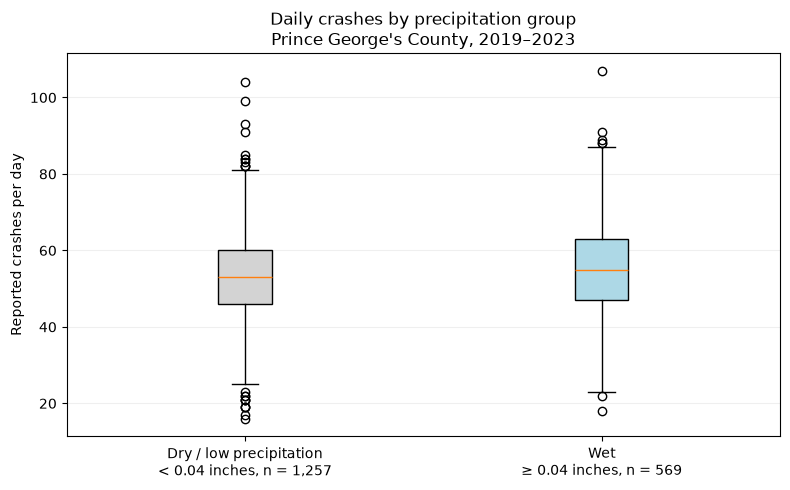

In [233]:
plt.figure(figsize=(8, 5))

boxes = plt.boxplot([dry, wet], patch_artist=True)
boxes["boxes"][0].set_facecolor("lightgray")
boxes["boxes"][1].set_facecolor("lightblue")

plt.xticks(
    [1, 2],
    ["Dry / low precipitation\n< 0.04 inches, n = 1,257",
     "Wet\n≥ 0.04 inches, n = 569"]
)
plt.ylabel("Reported crashes per day")
plt.title("Daily crashes by precipitation group\nPrince George's County, 2019–2023")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig("wet_vs_dry_crashes.png", dpi=300)
plt.show()

## Results

The boxplot compares daily crash counts in the two groups.
The boxes show the middle 50% of values, and the lines inside show
the medians.

The 569 wet days averaged 55.30 crashes, while the 1,257 dry/low-
precipitation days averaged 53.07. The difference, calculated before
rounding, was 2.24 crashes per day, with a 95% confidence interval
of 1.03–3.44.

Welch’s test gave t = 3.639 and p = 0.000287. Since p < 0.05,
we reject the null hypothesis under the test’s assumptions.
Wet days had a higher average crash count, although the groups
overlap considerably.

## Limitations

The test assumes independent observations, but nearby days may be
related. We also did not adjust for season, weekday, or pandemic-era
travel changes, so the p-value and confidence interval need caution.

Station averages approximate county weather, and the result depends
on our wet-day cutoff. Without traffic-volume data, this comparison
does not measure risk per trip or show that rain causes crashes.

In [234]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt




In [235]:
import os
print(os.getcwd())   # shows where the notebook is running


/Users/laurensimms/Downloads/maryland-precipitation-crashes-main


In [236]:
#combine all the datasets together

RAW = "maryland_crash_data/raw"
years = [2019, 2020, 2021, 2022, 2023] 

data = {}
for y in years:
    data[y] = pd.read_csv(f"{RAW}/CrashMap_REPORT_{y}.csv", low_memory=False)
    data[y]["Crashdate"] = pd.to_datetime(data[y]["Crashdate"], errors="coerce")
    print(y, data[y].shape,
          data[y]["Crashdate"].min().date(), "to", data[y]["Crashdate"].max().date(),
          "| unique reports:", data[y]["Reportnumber"].nunique())

2019 (116087, 9) 2019-01-01 to 2019-12-31 | unique reports: 116087


2020 (95714, 9) 2020-01-01 to 2020-12-31 | unique reports: 95714
2021 (108969, 9) 2021-01-01 to 2021-12-31 | unique reports: 108969
2022 (108600, 9) 2022-01-01 to 2022-12-31 | unique reports: 108600
2023 (110472, 9) 2023-01-01 to 2023-12-31 | unique reports: 110472


In [237]:
#stack the datasets together

df=pd.concat(data.values(), ignore_index=True)

print(df.shape)
print(df["Reportnumber"].duplicated().sum())
df["year"]=df["Crashdate"].dt.year
print(df["year"].value_counts().sort_index())

df.to_csv("MD_crashes_2019_2023.csv", index=False)

(539842, 9)
0
year
2019    116087
2020     95714
2021    108969
2022    108600
2023    110472
Name: count, dtype: int64


In [238]:
print(df["UseData"].value_counts(dropna=False).head(10))
print(df["Reporttype"].value_counts(dropna=False))
print(df["CountyOfCrash"].value_counts(dropna=False))
print(df.isna().mean().round(3))
print(df[["Latitude", "Longitude"]].describe())

UseData
True    539842
Name: count, dtype: int64
Reporttype
Property Damage Crash    393470
Injury Crash             143596
Fatal Crash                2776
Name: count, dtype: int64
CountyOfCrash
Baltimore          100876
Prince George's     98172
Baltimore City      84181
Montgomery          60099
Anne Arundel        47896
Howard              18853
Frederick           16654
Harford             16063
Charles             14082
Washington          12393
Wicomico            10498
Carroll              9501
Cecil                8248
St. Mary's           8140
Worcester            6863
Calvert              5200
Queen Anne's         4043
Talbot               3851
Allegany             3714
Dorchester           2717
Caroline             2513
Garrett              2467
Somerset             1616
Kent                 1202
Name: count, dtype: int64
Reportnumber     0.0
AgencyCode       0.0
CountyOfCrash    0.0
Reporttype       0.0
UseData          0.0
Crashdate        0.0
CrashPoint       0.0
Latitud

In [239]:
#get rid of bad coordinates
in_md=df["Latitude"].between(37.9, 39.73) & df["Longitude"].between(-79.5, -75.0)
df.loc[~in_md & df["Latitude"].notna(), ["Reportnumber", "CountyOfCrash", "Latitude", "Longitude"]].head(20)

df=df.drop(columns=["UseData", "CrashPoint"])

df["Latitude"]= df["Latitude"].where(in_md)
df["Longitude"]=df["Longitude"].where(in_md)

In [240]:
df["Crashdate"]= pd.to_datetime(df["Crashdate"], errors="coerce")
df["year"]= df["Crashdate"].dt.year
df["month"]= df["Crashdate"].dt.month

type_map={
    "Property Damage Crash": "property_damage_crashes",
    "Injury Crash": "injury_crashes",
    "Fatal Crash": "fatal_crashes",
}

df["crash_type"]= df["Reporttype"].map(type_map)

monthly=(
    df.groupby(["CountyOfCrash", "year", "month", "crash_type"])
    .size().unstack("crash_type", fill_value=0).reset_index().rename(columns={"CountyOfCrash": "county"})
)

countries= monthly["county"].unique()
full= pd.MultiIndex.from_product([countries, range(2019,2024), range(1,13)], names=["county", "year", "month"])
monthly= (monthly.set_index(["county", "year", "month"]).reindex(full, fill_value=0).reset_index())

monthly["total_crashes"]=(monthly["property_damage_crashes"]+monthly["injury_crashes"]+monthly["fatal_crashes"])
monthly["injury_or_fatal_crashes"]= monthly["injury_crashes"]+monthly["fatal_crashes"]

monthly["year_month"]=pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
monthly["days_in_month"]= monthly["year_month"].dt.days_in_month
monthly["crashes_per_day"]=(monthly["total_crashes"]/monthly["days_in_month"]).round(2)

monthly.to_csv("maryland_crash_data/cleaned/md_crashes_by_county_month.csv", index=False)

In [241]:
print(monthly.shape)
print(monthly["total_crashes"].sum())
print(monthly["county"].nunique())
print(monthly.groupby("year")["total_crashes"].sum())

(1440, 11)
539842
24
year
2019    116087
2020     95714
2021    108969
2022    108600
2023    110472
Name: total_crashes, dtype: int64


In [242]:
monthly= monthly.sort_values(["county", "year", "month"]).reset_index(drop=True)
monthly.head(12)
print(monthly.dtypes)
print((monthly["total_crashes"]==0).sum())

crash_type
county                                str
year                                int32
month                               int32
fatal_crashes                       int64
injury_crashes                      int64
property_damage_crashes             int64
total_crashes                       int64
injury_or_fatal_crashes             int64
year_month                 datetime64[us]
days_in_month                       int32
crashes_per_day                   float64
dtype: object
0


In [243]:
print(sorted(monthly["county"].unique()))

['Allegany', 'Anne Arundel', 'Baltimore', 'Baltimore City', 'Calvert', 'Caroline', 'Carroll', 'Cecil', 'Charles', 'Dorchester', 'Frederick', 'Garrett', 'Harford', 'Howard', 'Kent', 'Montgomery', "Prince George's", "Queen Anne's", 'Somerset', "St. Mary's", 'Talbot', 'Washington', 'Wicomico', 'Worcester']


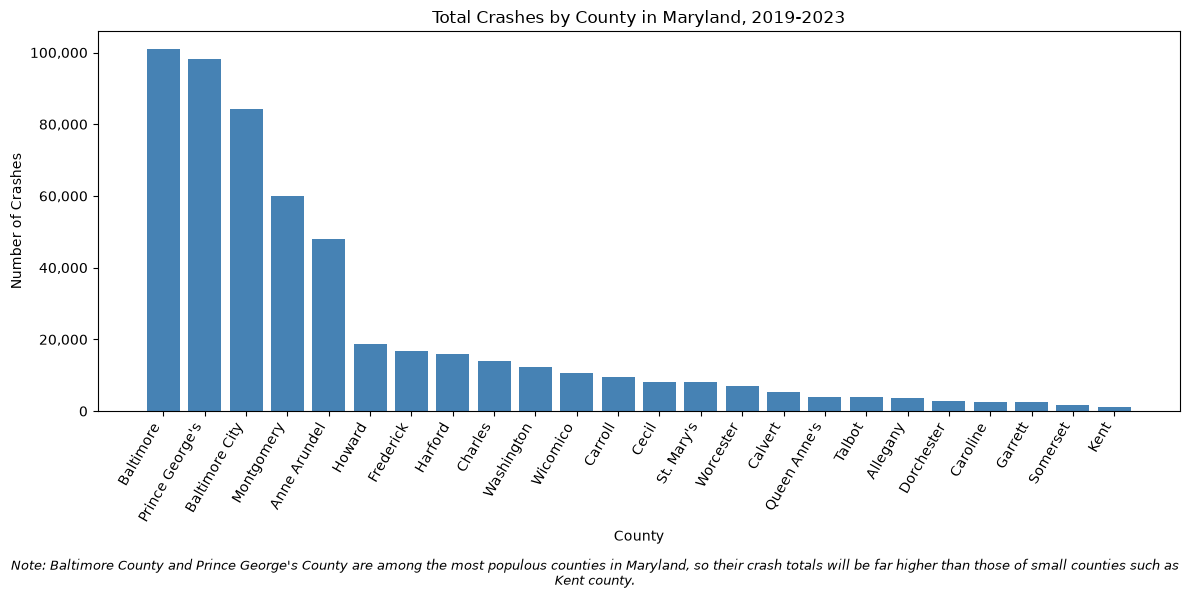

In [244]:
#graph

by_county= (monthly.groupby("county")["total_crashes"].sum().sort_values(ascending=False))

fig, ax=plt.subplots(figsize=(12,6))
ax.bar(by_county.index, by_county.values, color="Steelblue")

ax.set_title("Total Crashes by County in Maryland, 2019-2023")
ax.set_xlabel("County")
ax.set_ylabel("Number of Crashes")
ax.set_xticks(range(len(by_county)))
ax.set_xticklabels(by_county.index, rotation=60, ha="right")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _:f"{int(x):,}"))

note=("Note: Baltimore County and Prince George's County are among the most populous counties in Maryland, so their crash totals will be far higher than those of small counties such as Kent county.")
fig.text(0.5, 0.01, note, ha="center", va="bottom", fontsize=9, style="italic", wrap=True)

plt.tight_layout(rect=[0,0.06,1,1])
plt.savefig("crashes_by_county.png", dpi=200)
plt.show()

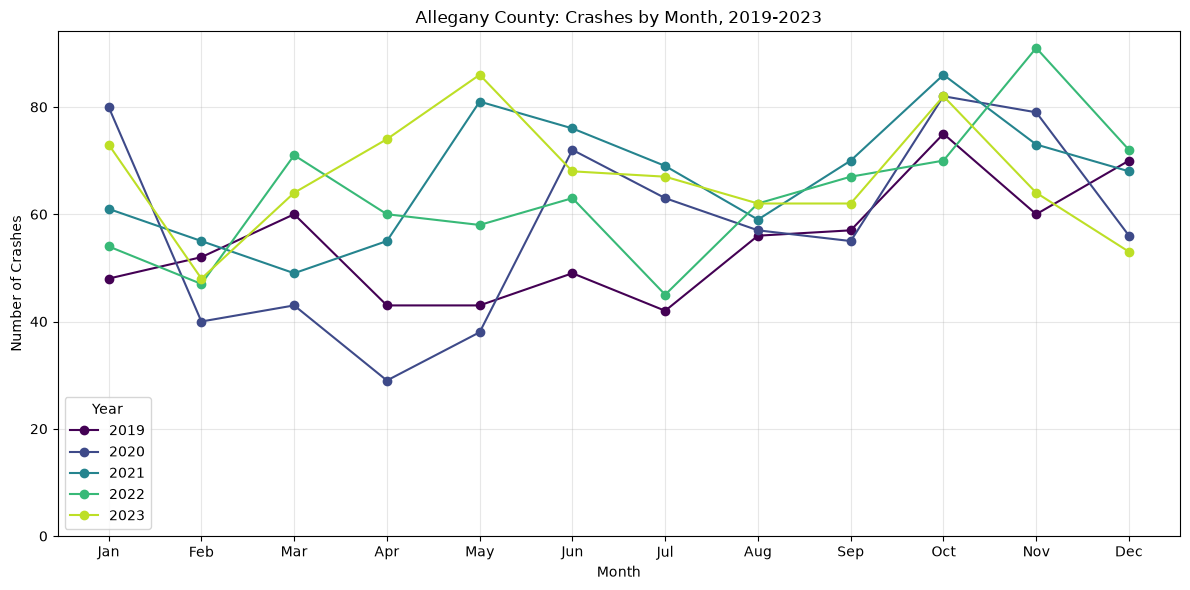

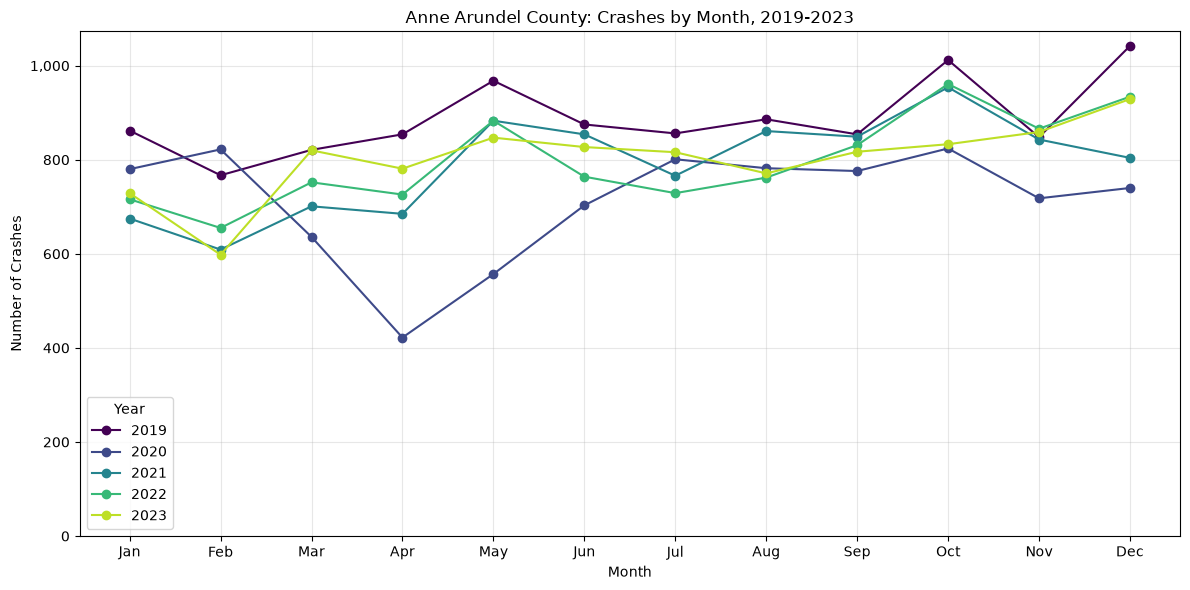

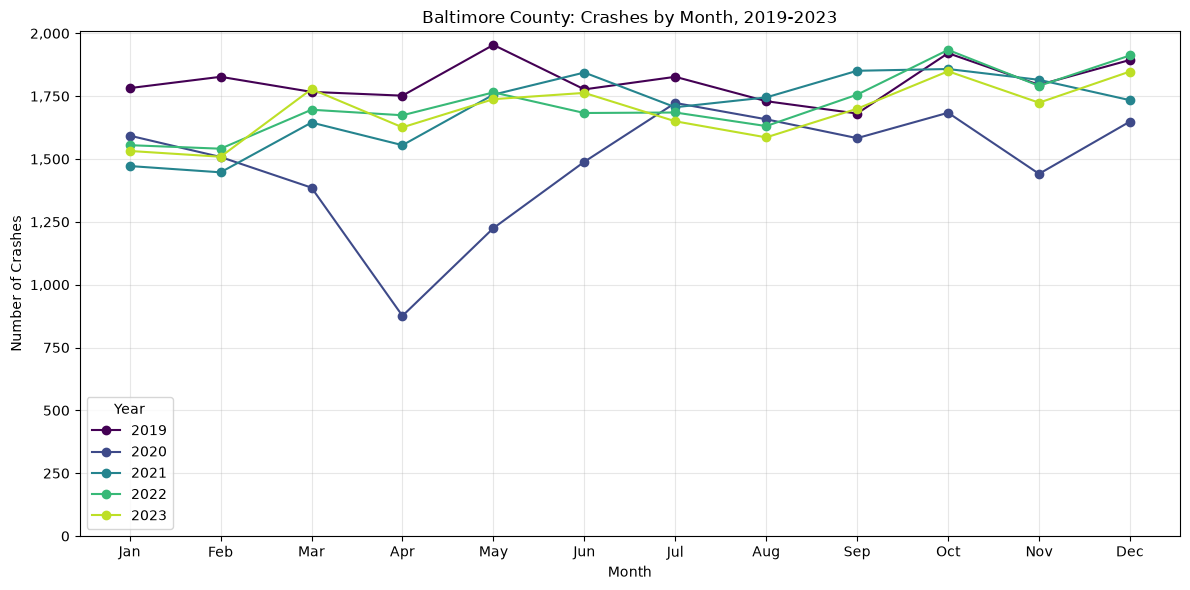

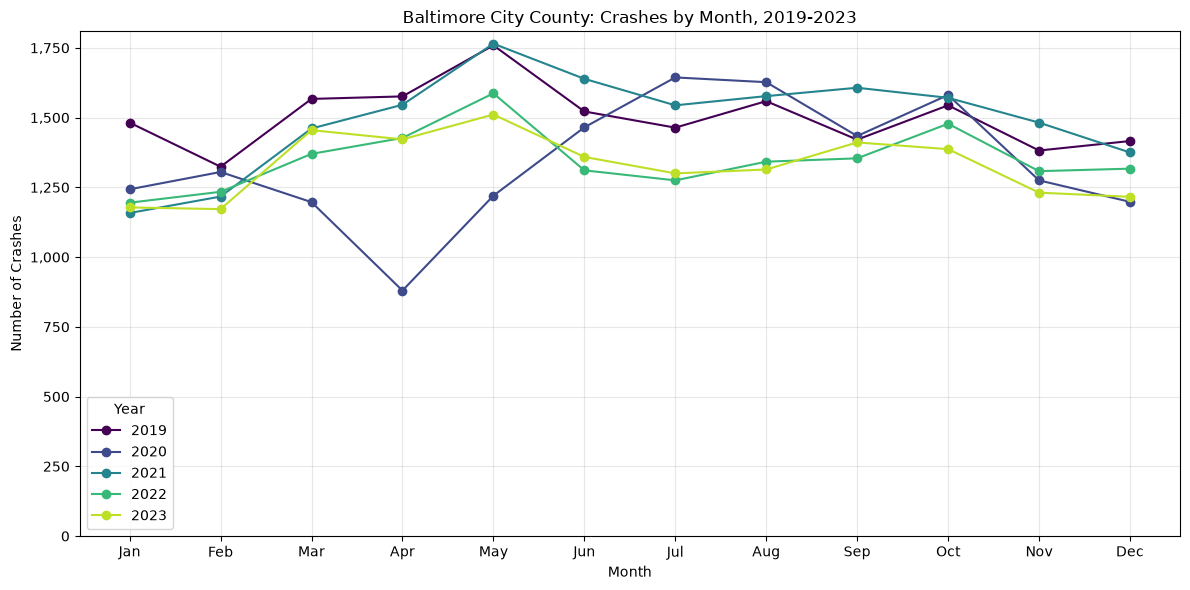

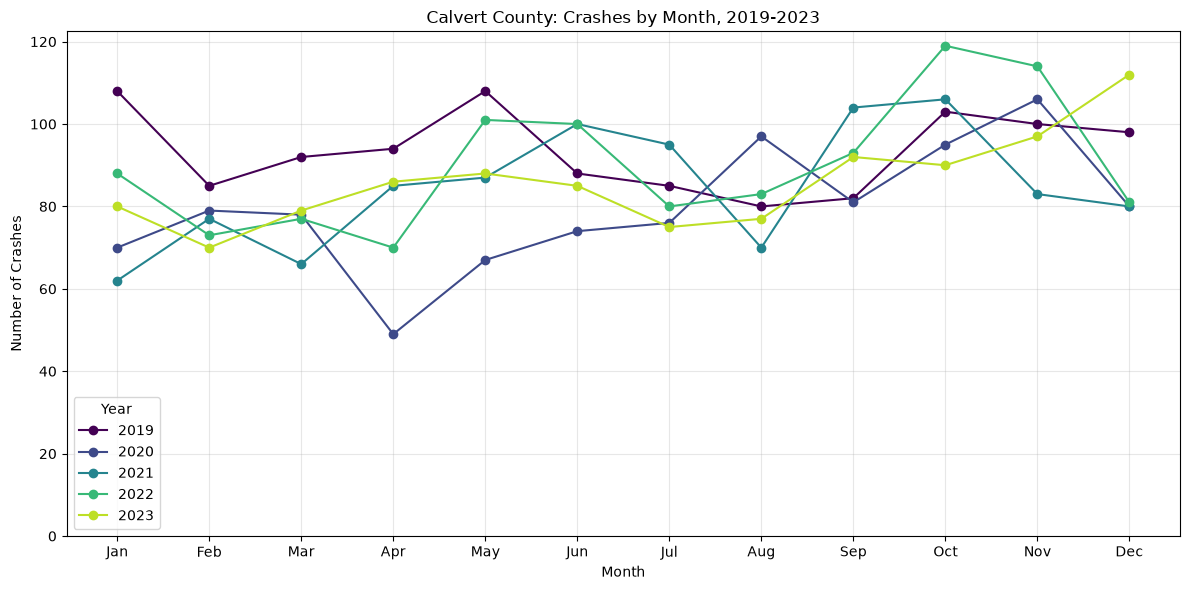

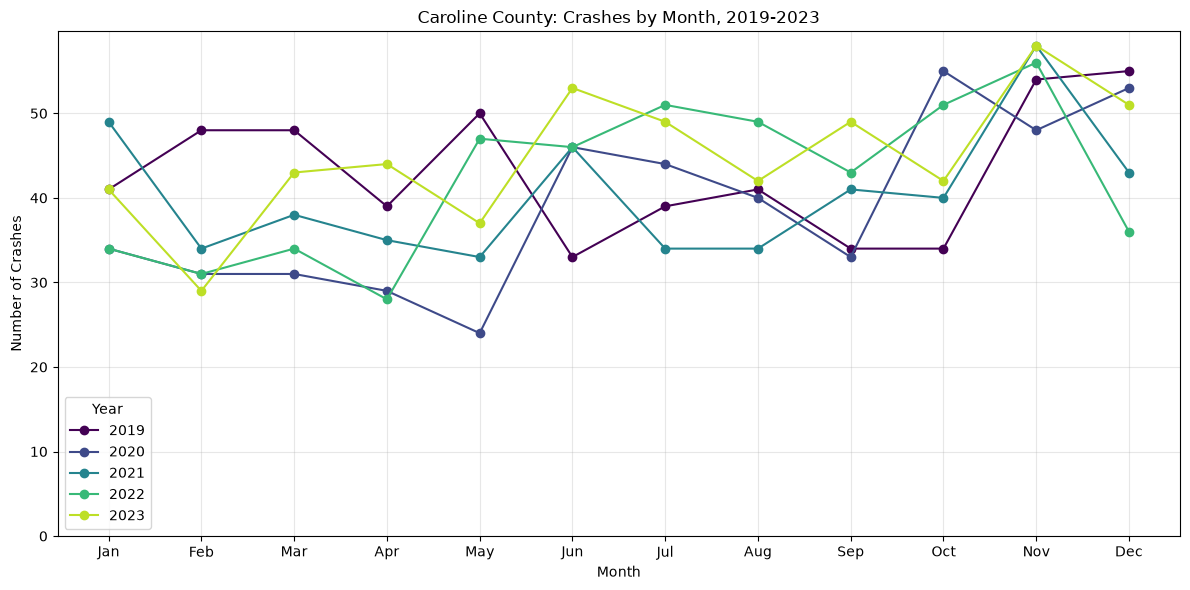

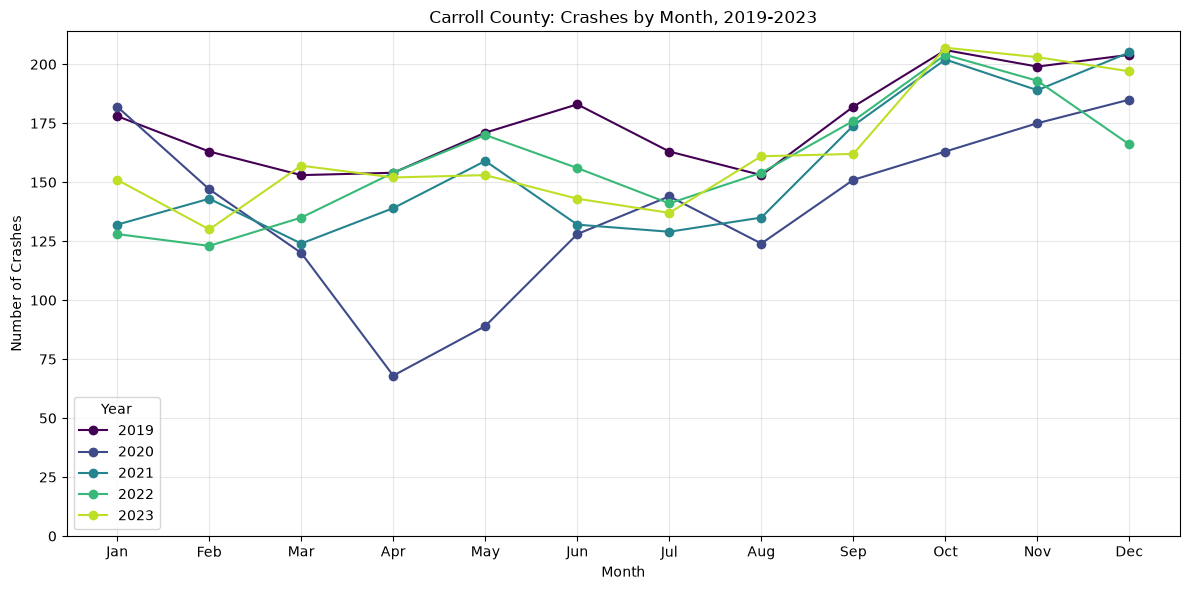

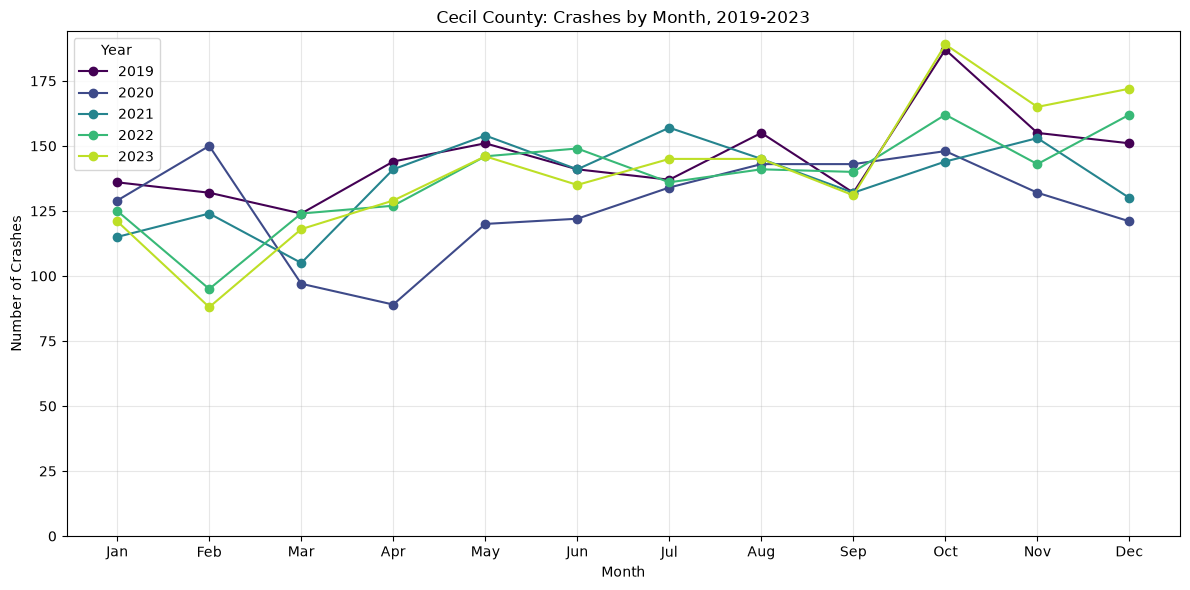

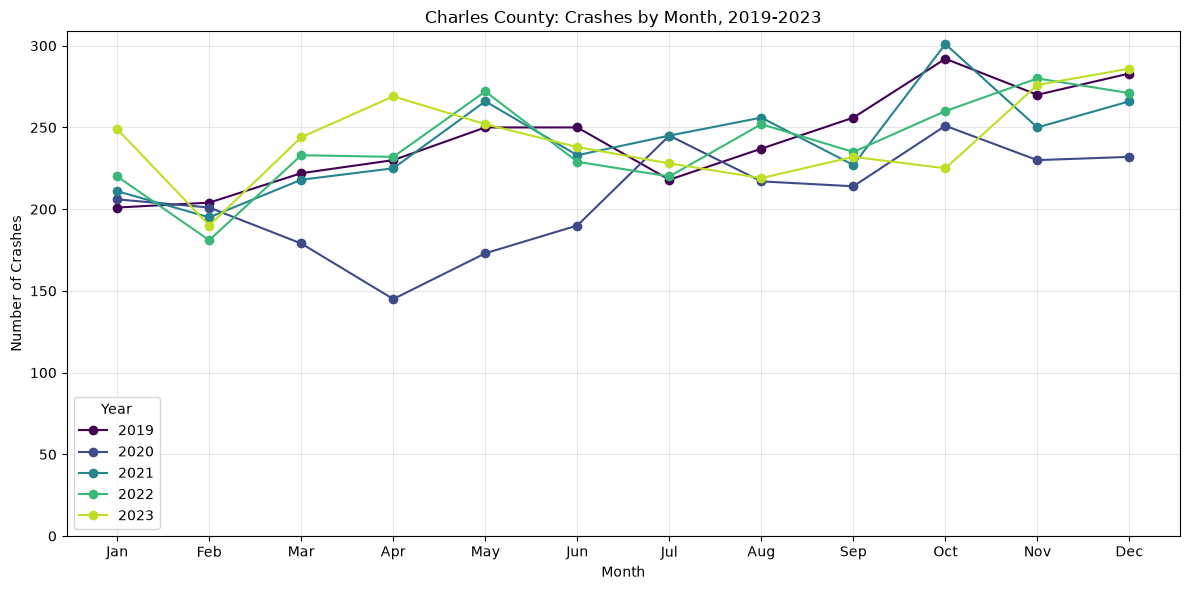

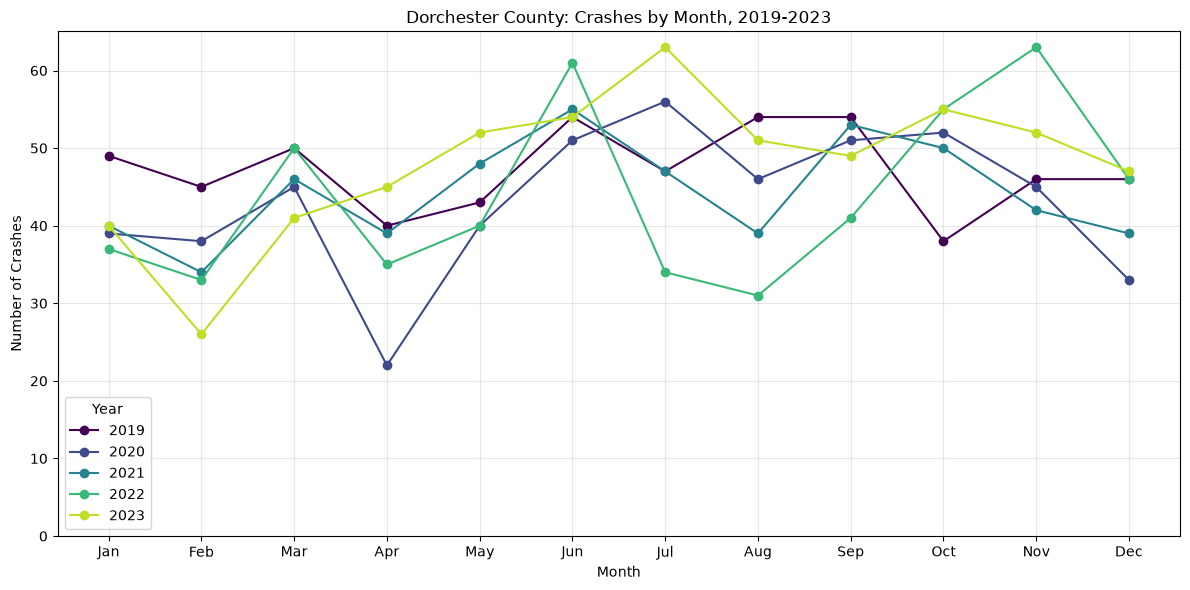

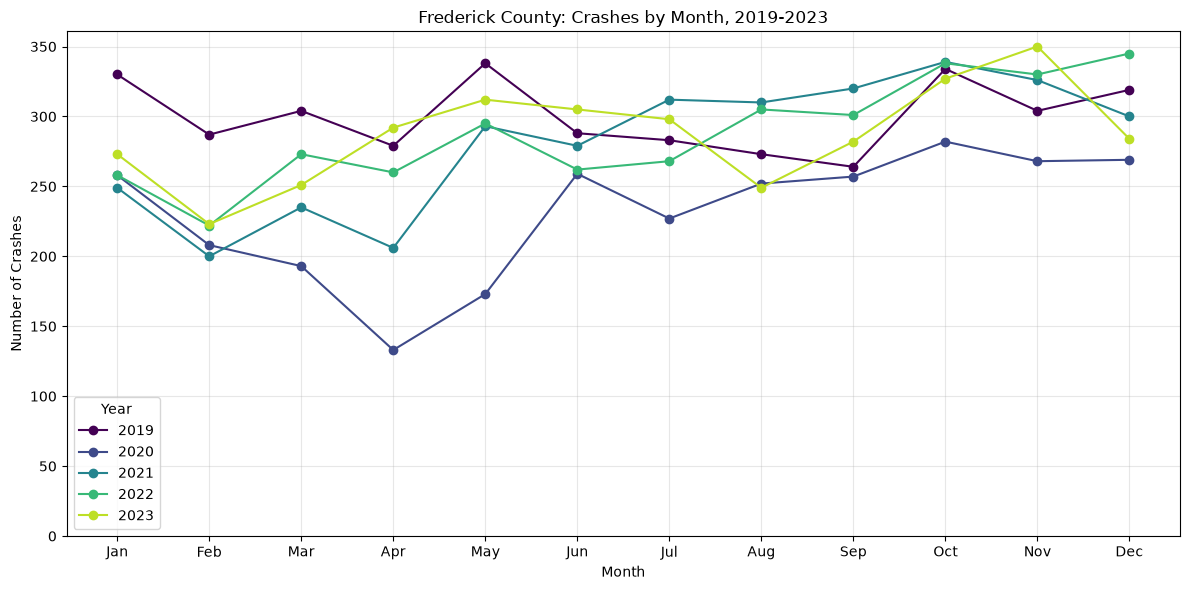

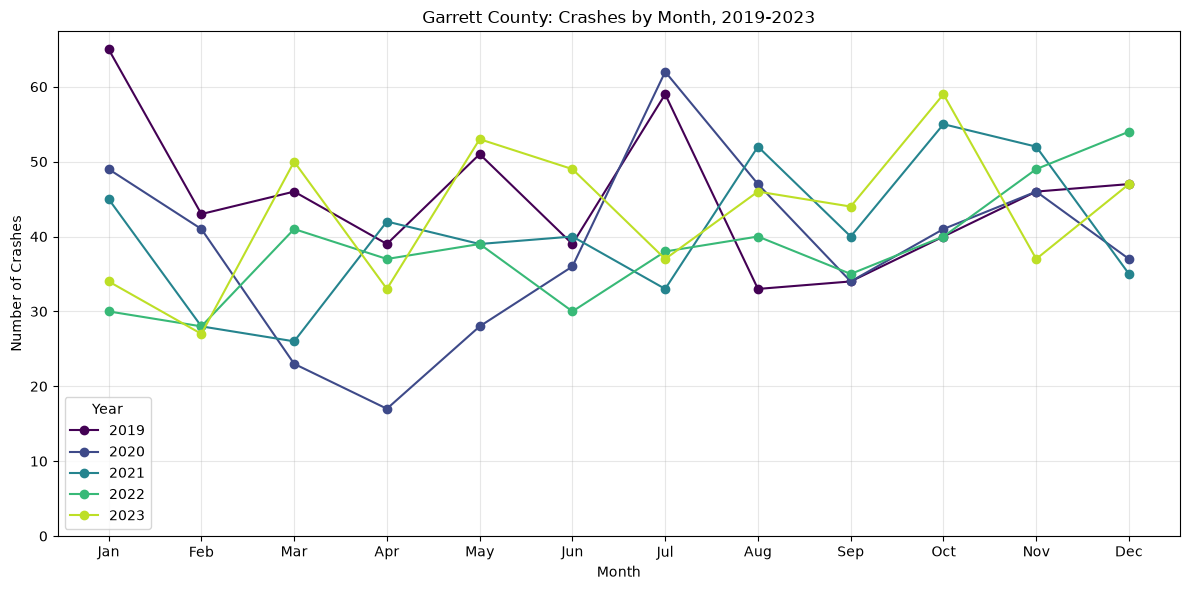

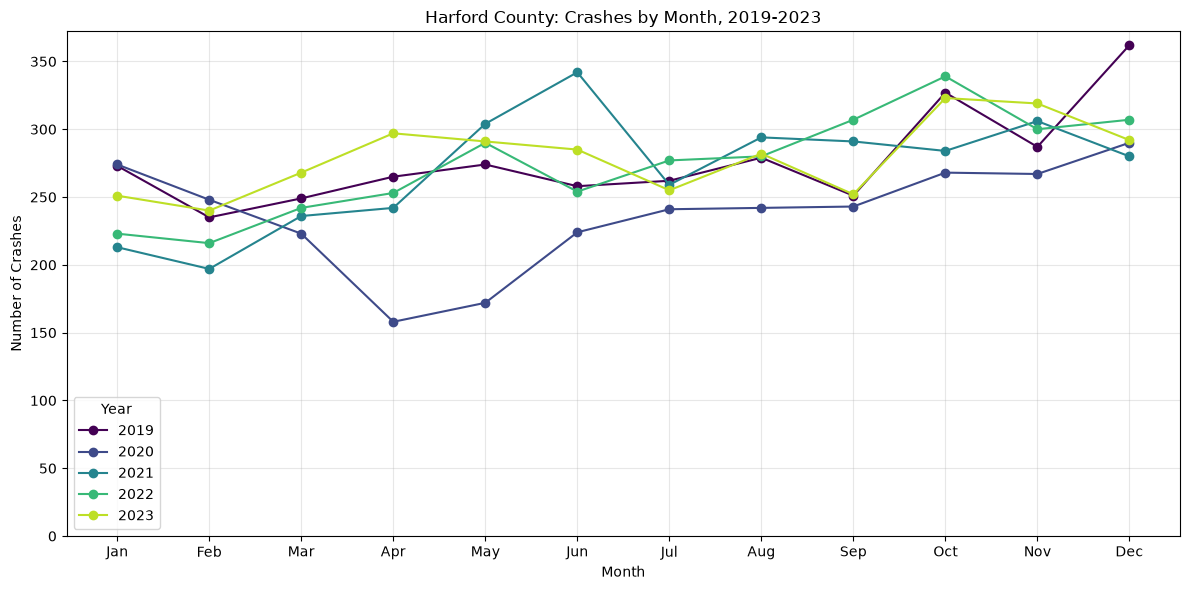

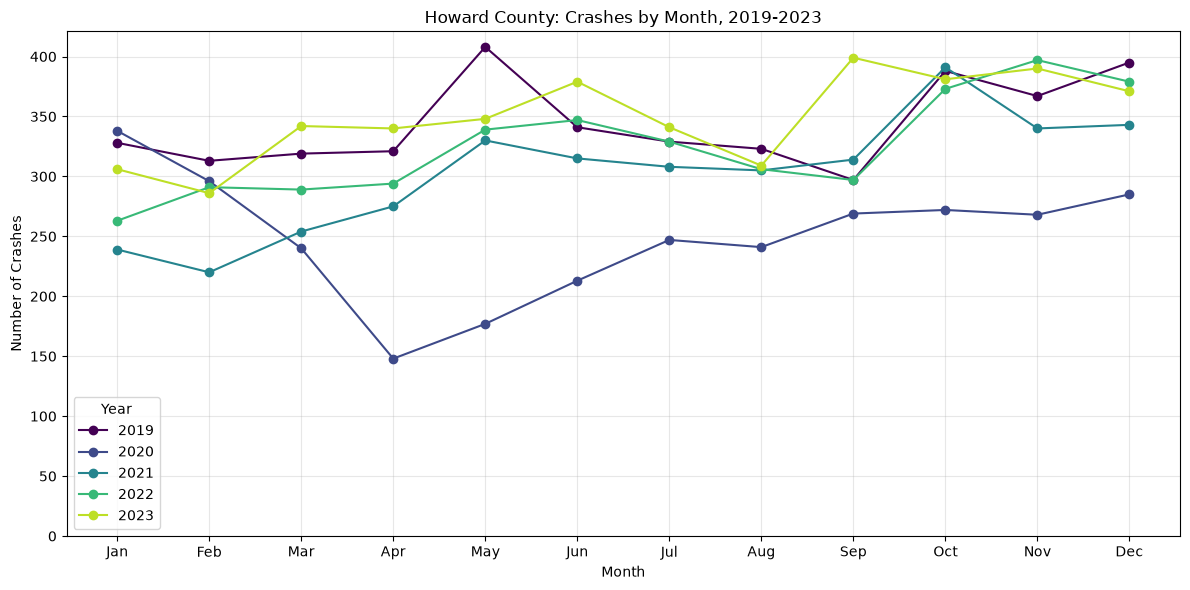

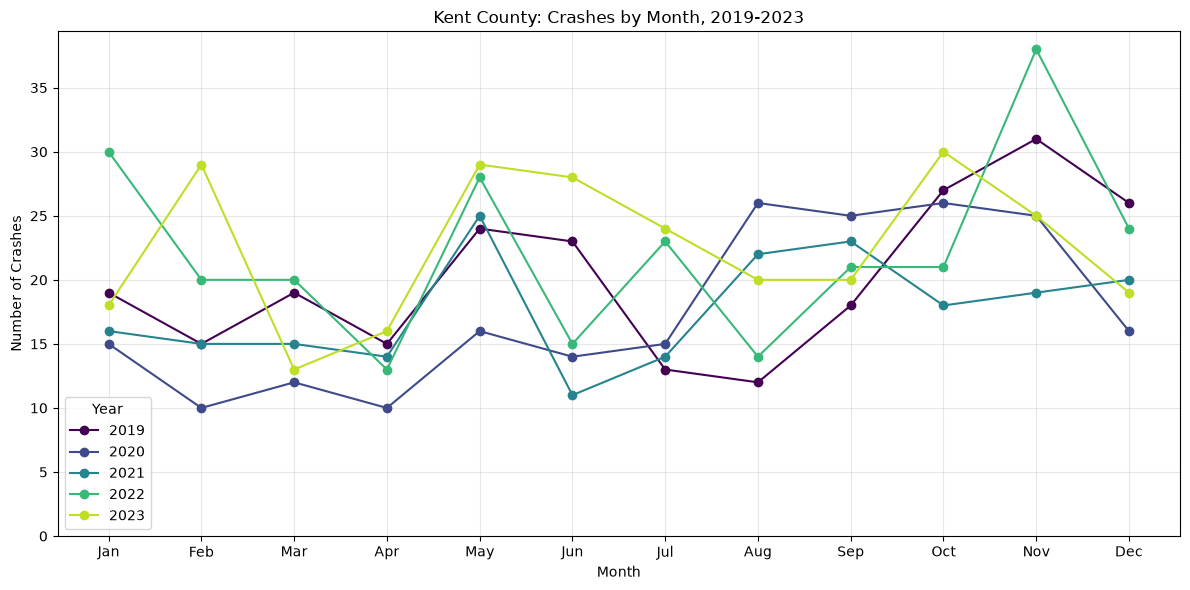

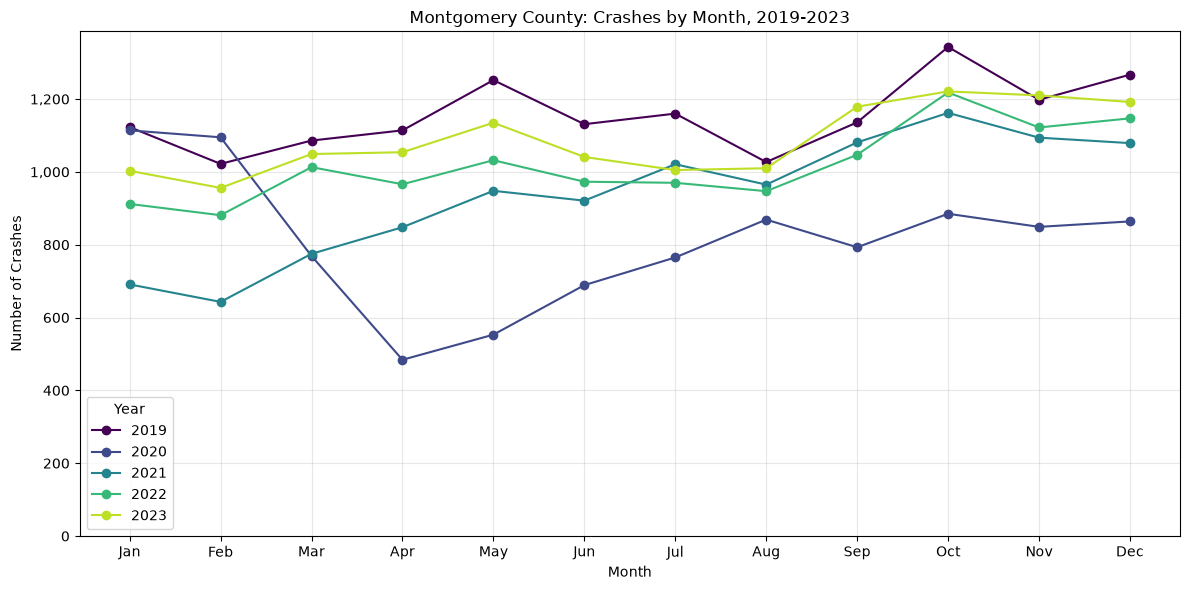

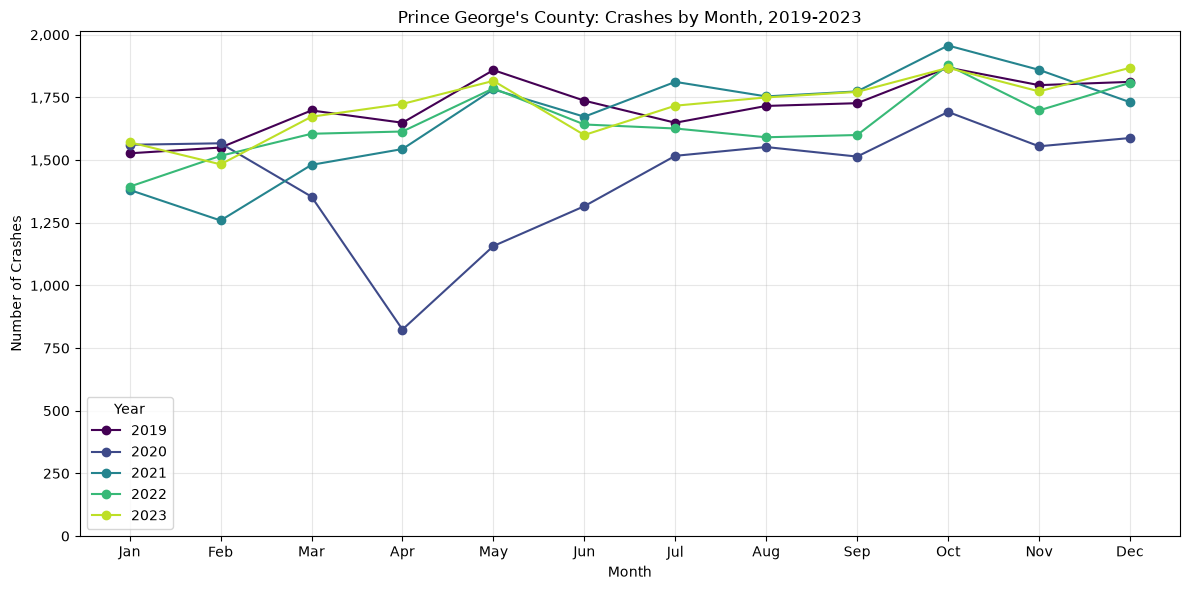

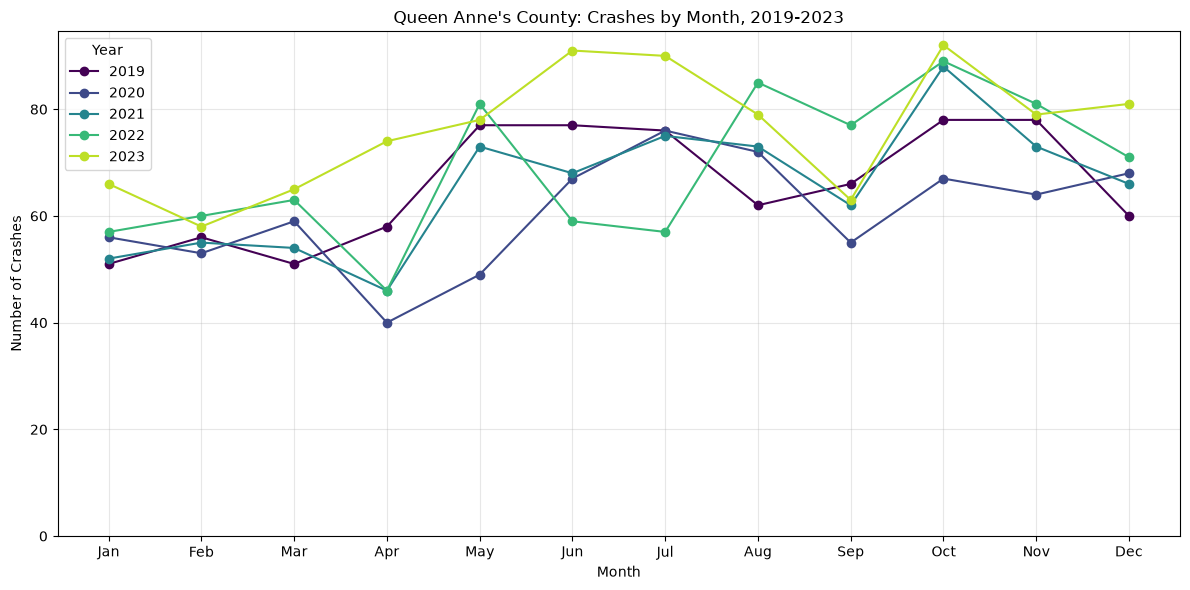

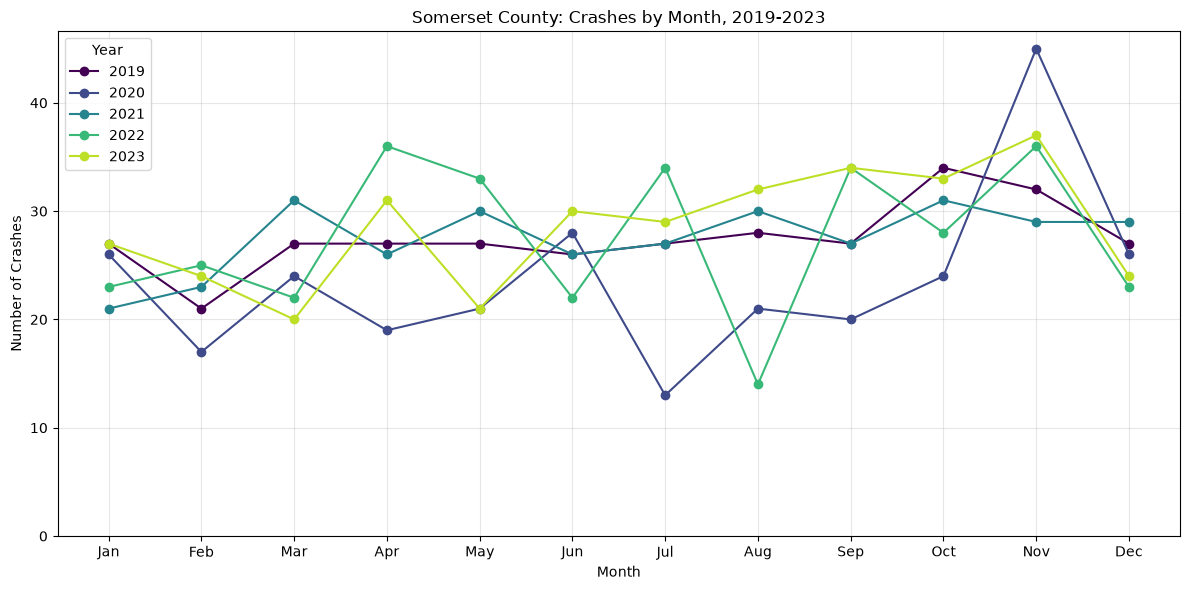

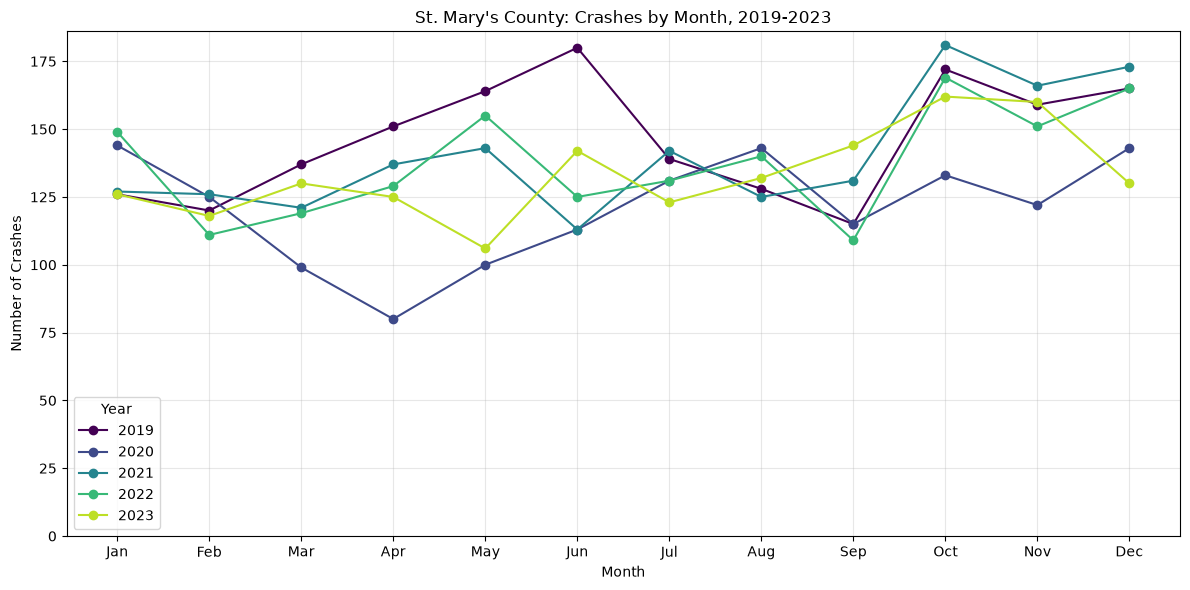

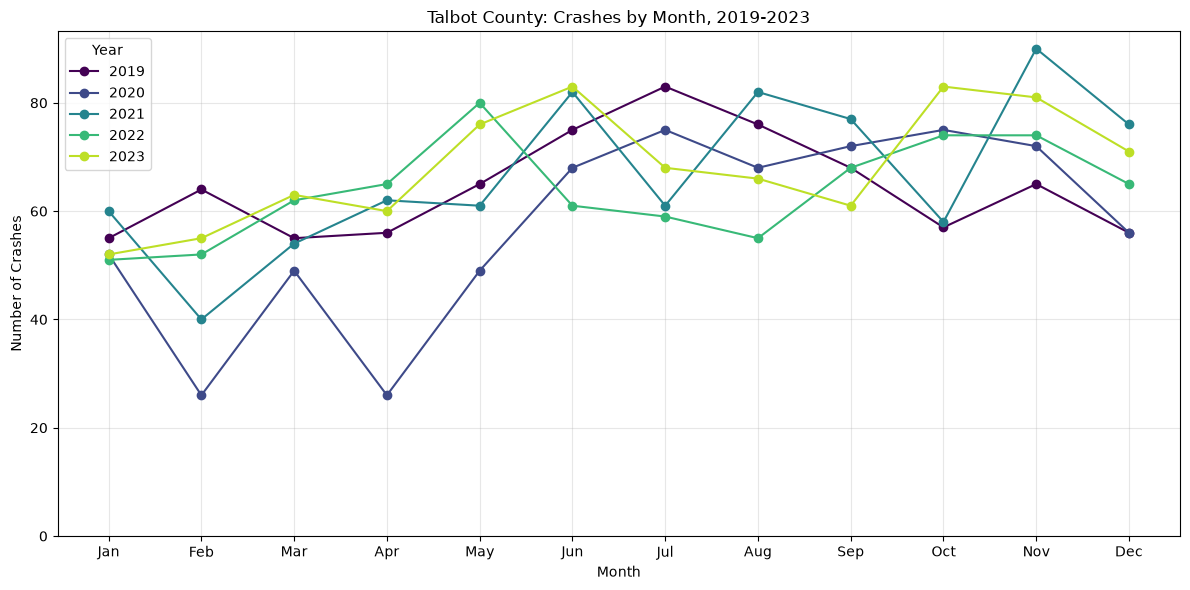

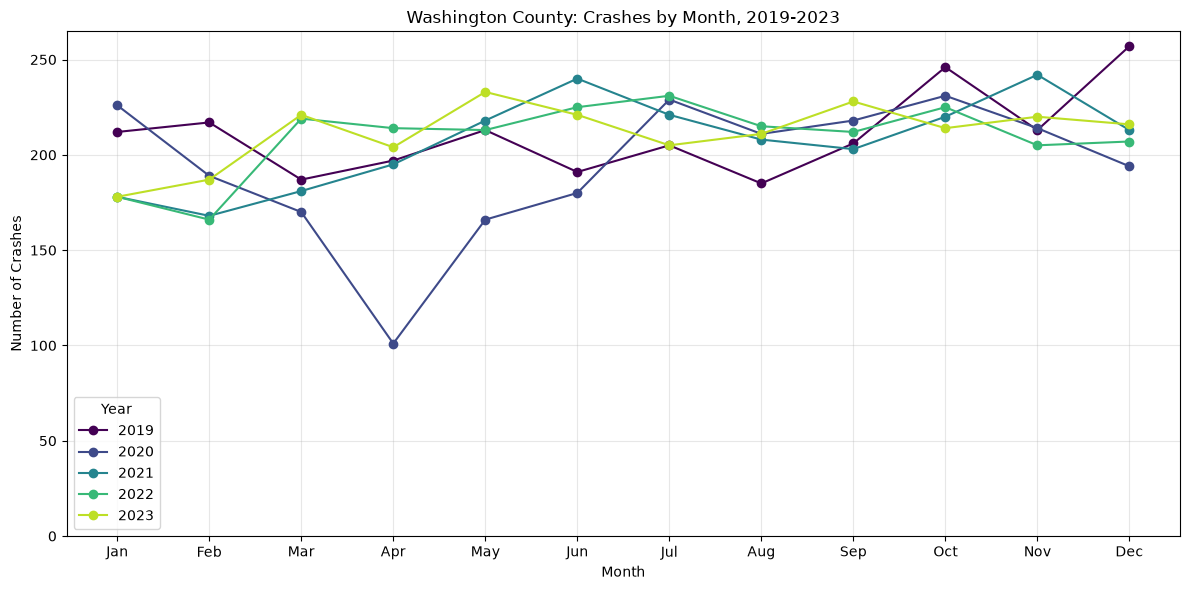

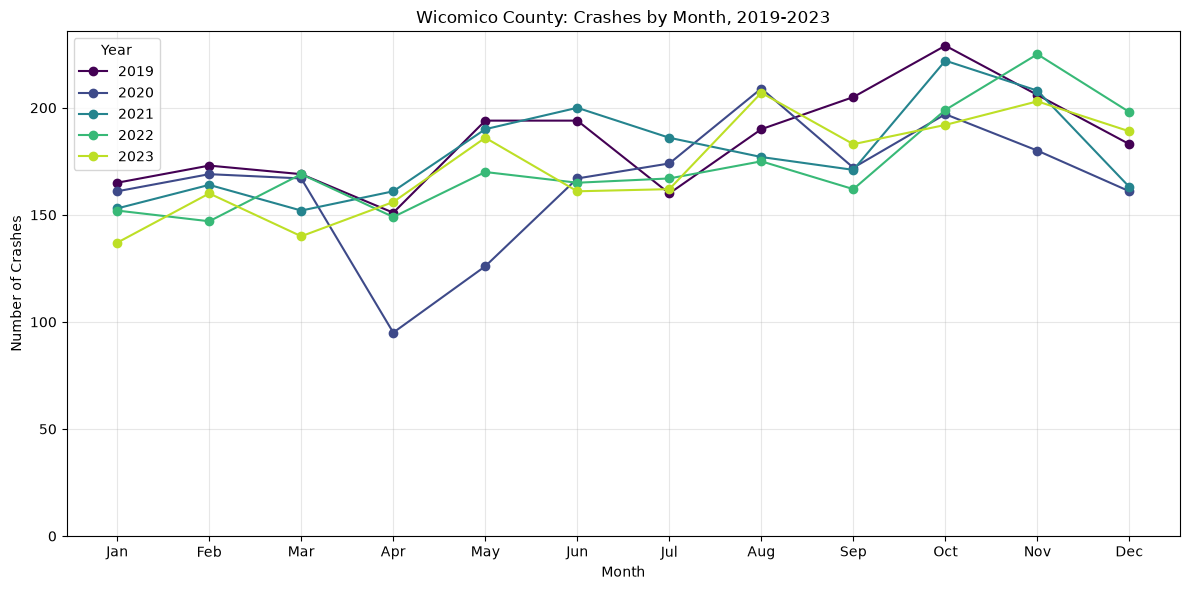

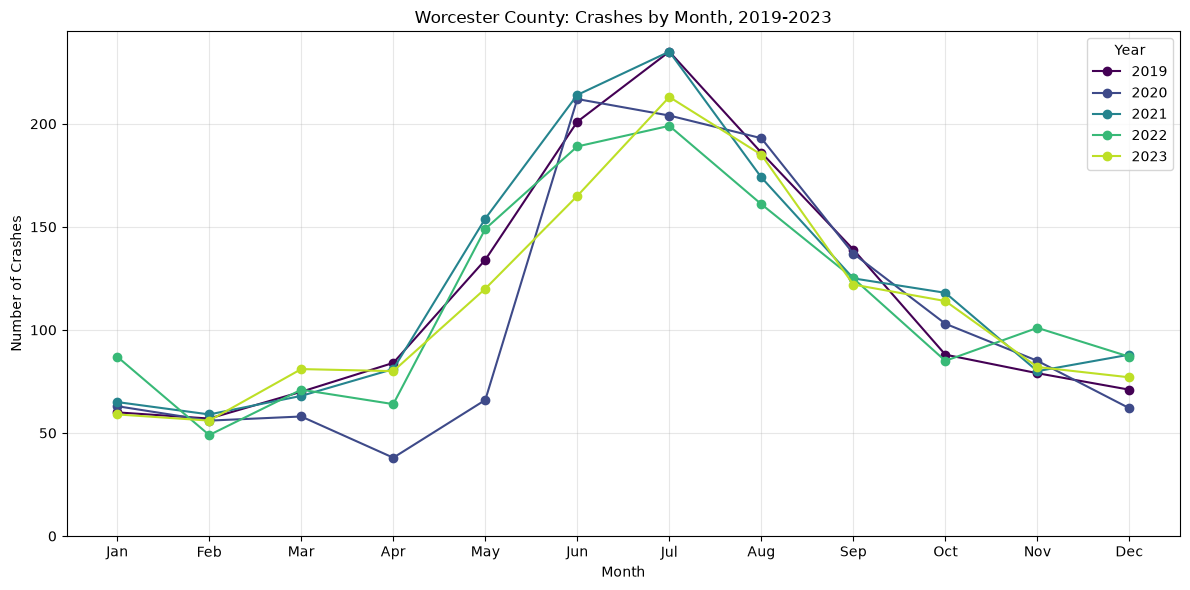

In [245]:
#Crash data by county for year range
import os                                      
os.makedirs("crash_charts", exist_ok=True)  

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def county_monthly_chart(county, filename=None):
    d = monthly[monthly["county"] == county]
    pivot = d.pivot(index="month", columns="year", values="total_crashes")   # 12 rows x 5 years

    fig, ax = plt.subplots(figsize=(12, 6))
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(pivot.columns)))
    for color, yr in zip(colors, pivot.columns):
        ax.plot(pivot.index, pivot[yr], marker="o", label=str(yr), color=color)

    ax.set_title(f"{county} County: Crashes by Month, 2019-2023")
    ax.set_xlabel("Month")
    ax.set_ylabel("Number of Crashes")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend(title="Year")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

    plt.tight_layout()
    if filename is None:
        filename = f"monthly_crashes_{county.replace(' ', '_').replace(chr(39), '')}.png"
    plt.savefig(os.path.join("crash_charts", filename), dpi=200)
    plt.show()
    plt.close(fig)


for c in sorted(monthly["county"].unique()):
    county_monthly_chart(c)

In [246]:
#population tables
tla = pd.read_excel("maryland_crash_data/raw/County-table1A.xlsx", header=None)

counties = sorted(monthly["county"].unique())   # moved up

#data copied from pdf from planning.maryland.gov
vals_2019 = {
    "Allegany": 68575,
    "Anne Arundel": 585330,
    "Baltimore": 853764,
    "Baltimore City": 591876,
    "Calvert": 92431,
    "Caroline": 33306,
    "Carroll": 172278,
    "Cecil": 103381,
    "Charles": 165794,
    "Dorchester": 32461,
    "Frederick": 267598,
    "Garrett": 28947,
    "Harford": 259590,
    "Howard": 330064,
    "Kent": 19347,
    "Montgomery": 1060001,
    "Prince George's": 963706,
    "Queen Anne's": 49504,
    "Somerset": 24811,
    "St. Mary's": 113109,
    "Talbot": 37610,
    "Washington": 154341,
    "Wicomico": 103608,
    "Worcester": 52337,
}

pop_2019 = pd.DataFrame({
    "county": list(vals_2019.keys()),
    "year": 2019,
    "population": list(vals_2019.values()),
})

#2020-2023 from Table 1A
sub = tla[[0, 2, 3, 4, 5]].copy()
sub.columns = ["county", 2020, 2021, 2022, 2023]
sub["county"] = sub["county"].astype(str).str.replace(" County", "", regex=False).str.strip()
sub = sub[sub["county"].isin(counties)]

print(len(sub))                                 
print(set(counties) - set(sub["county"]))        
print(set(counties) - set(pop_2019["county"]))   
print(set(pop_2019["county"]) - set(counties))   

pop_2020_23 = sub.melt(id_vars="county", var_name="year", value_name="population")
pop_2020_23["population"] = pd.to_numeric(pop_2020_23["population"])
pop_2020_23["year"] = pop_2020_23["year"].astype(int)

print(pop_2019["population"].sum())              

#combine 2019 with 2020-2023 data
pop = pd.concat([pop_2019, pop_2020_23], ignore_index=True)
pop["year"] = pop["year"].astype(int)

print(pop.shape)                                 
print(pop.groupby("year")["population"].sum())
print(pop.pivot(index="county", columns="year", values="population"))

pop.to_csv("maryland_crash_data/md_population.csv", index=False)

24
set()
set()
set()
6163769
(120, 3)
year
2019    6163769
2020    6177935
2021    6179403
2022    6192440
2023    6217062
Name: population, dtype: int64
year                2019     2020     2021     2022     2023
county                                                      
Allegany           68575    67950    67671    67241    67296
Anne Arundel      585330   593412   596354   598751   599965
Baltimore         853764   853338   850670   848873   848676
Baltimore City    591876   583189   576575   570663   567517
Calvert            92431    92921    94249    94652    94828
Caroline           33306    33277    33443    33539    33838
Carroll           172278   172910   174282   175569   176735
Cecil             103381   103805   104073   104939   105676
Charles           165794   166692   168822   170376   172268
Dorchester         32461    32523    32590    32599    32922
Frederick         267598   272787   280666   288316   294154
Garrett            28947    28797    28766    28619  

In [247]:
from scipy.stats import pearsonr, spearmanr

county_totals = monthly.groupby("county")["total_crashes"].sum()
avg_pop = pop.groupby("county")["population"].mean()
cdf = pd.concat([county_totals, avg_pop], axis=1).reset_index()

print(cdf["total_crashes"].sum())    # 539842
print(cdf.sort_values("total_crashes", ascending=False).head(5))

r, p_r = pearsonr(cdf["population"], cdf["total_crashes"])
rho, p_s = spearmanr(cdf["population"], cdf["total_crashes"])
print(f"Pearson r = {r:.3f} (p = {p_r:.4g})")
print(f"Spearman rho = {rho:.3f} (p = {p_s:.4g})")


539842
             county  total_crashes  population
2         Baltimore         100876    851064.2
16  Prince George's          98172    959169.8
3    Baltimore City          84181    577964.0
15       Montgomery          60099   1061494.6
1      Anne Arundel          47896    594762.4
Pearson r = 0.922 (p = 1.595e-10)
Spearman rho = 0.974 (p = 1.163e-15)


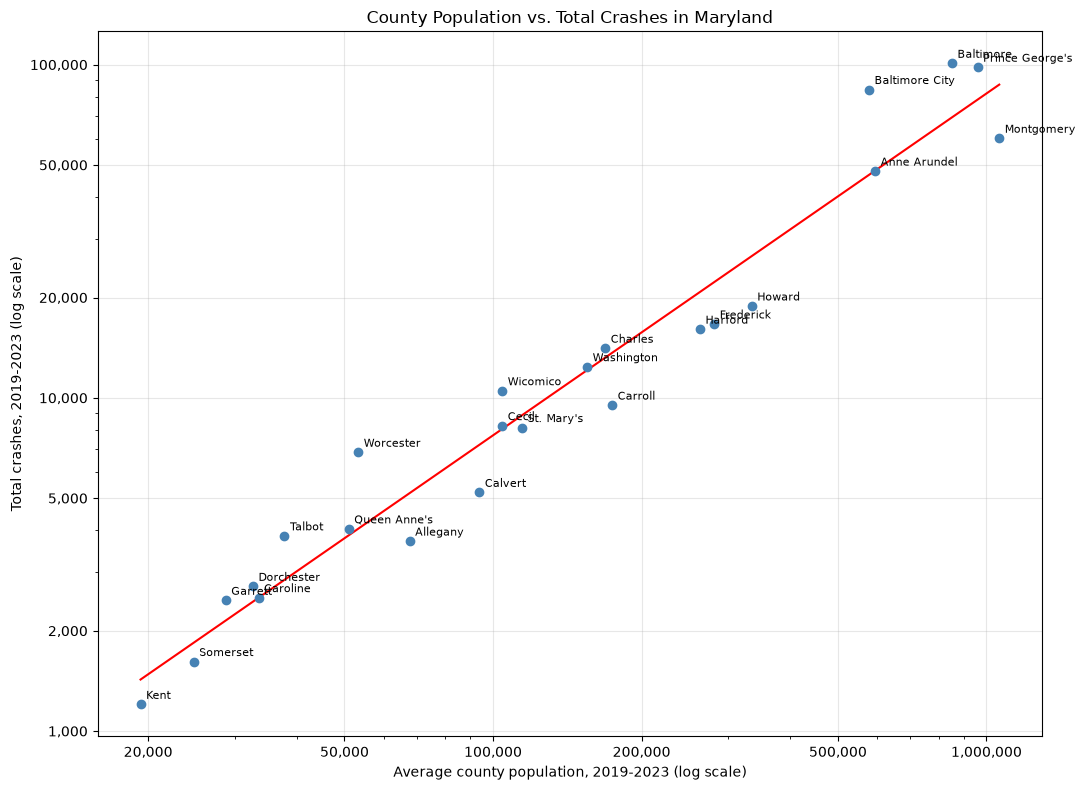

In [248]:
#correlation between amount of residents and crashes
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(cdf["population"], cdf["total_crashes"], color="steelblue", zorder=3)


ax.set_xscale("log")
ax.set_yscale("log")

xticks = [20_000, 50_000, 100_000, 200_000, 500_000, 1_000_000]
yticks = [1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000]
ax.xaxis.set_major_locator(FixedLocator(xticks))
ax.yaxis.set_major_locator(FixedLocator(yticks))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{int(y):,}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())


slope, intercept = np.polyfit(np.log10(cdf["population"]), np.log10(cdf["total_crashes"]), 1)
xs = np.linspace(cdf["population"].min(), cdf["population"].max(), 100)
ax.plot(xs, 10 ** (intercept + slope * np.log10(xs)), color="red", zorder=2)



for _, row in cdf.iterrows():
    ax.annotate(row["county"], (row["population"], row["total_crashes"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8)

ax.set_xlabel("Average county population, 2019-2023 (log scale)")
ax.set_ylabel("Total crashes, 2019-2023 (log scale)")
ax.set_title("County Population vs. Total Crashes in Maryland")
ax.grid(alpha=0.3, which="major")
plt.tight_layout()
plt.savefig("population_vs_crashes.png", dpi=200)
plt.show()